In [1]:
import geopandas as gpd

In [2]:
LOANS_FILE = "../datasets/geospatial-learn-course-data/kiva_loans/kiva_loans.shp"

# Load the data
world_loans = gpd.read_file(LOANS_FILE)

# View the first five rows of the data
world_loans.head()

,Partner ID,Field Part,sector,Loan Theme,country,amount,geometry
0,9,KREDIT Microfinance Institution,General Financial Inclusion,Higher Education,Cambodia,450,POINT (102.89751 13.66726)
1,9,KREDIT Microfinance Institution,General Financial Inclusion,Vulnerable Populations,Cambodia,20275,POINT (102.98962 13.0287)
2,9,KREDIT Microfinance Institution,General Financial Inclusion,Higher Education,Cambodia,9150,POINT (102.98962 13.0287)
3,9,KREDIT Microfinance Institution,General Financial Inclusion,Vulnerable Populations,Cambodia,604950,POINT (105.31312 12.09829)
4,9,KREDIT Microfinance Institution,General Financial Inclusion,Sanitation,Cambodia,275,POINT (105.31312 12.09829)


In [3]:
WORLD_FILE = "../datasets/geospatial-learn-course-data/naturalearth_lowres/naturalearth_lowres.shp"
world = gpd.read_file(WORLD_FILE)
world.head()

,pop_est,continent,name,iso_a3,gdp_md_est,geometry
0,920938,Oceania,Fiji,FJI,8374.0,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,53950935,Africa,Tanzania,TZA,150600.0,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,603253,Africa,W. Sahara,ESH,906.5,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,35623680,North America,Canada,CAN,1674000.0,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,326625791,North America,United States of America,USA,18560000.0,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


<Axes: >

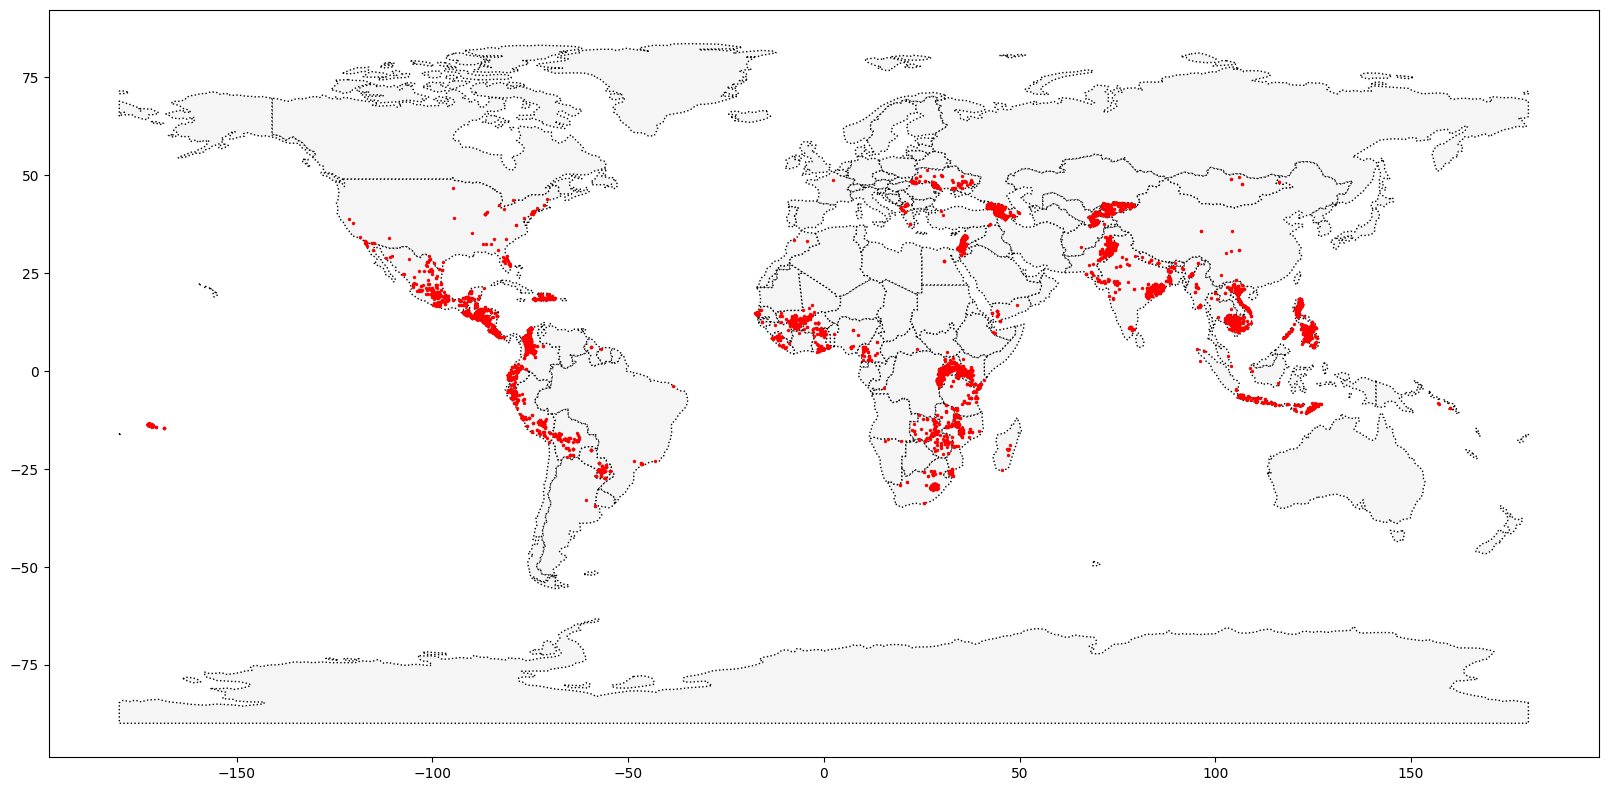

In [4]:
# Use the world and world_loans GeoDataFrames to visualize Kiva loan locations across the world.
ax = world.plot(figsize=(20,20), color='whitesmoke', edgecolor='black', linestyle=':')
world_loans.plot(ax=ax, color='red', markersize=2)

In [5]:
# Create a GeoDataFrame `PHL_loans` which contains all rows from `world_loans` with loans 
# that are based in the Philippines.
PHL_loans = world_loans.loc[world_loans.country == 'Philippines'].copy()

In [6]:
# Load a KML file containing island boundaries
import fiona

fiona.drvsupport.supported_drivers['KML'] = 'rw'
PHL = gpd.read_file("../datasets/geospatial-learn-course-data/Philippines_AL258.kml", driver='KML')
PHL.head()

,Name,Description,geometry
0,Autonomous Region in Muslim Mindanao,,"MULTIPOLYGON (((119.4669 4.58718, 119.46653 4...."
1,Bicol Region,,"MULTIPOLYGON (((124.04577 11.57862, 124.04594 ..."
2,Cagayan Valley,,"MULTIPOLYGON (((122.51581 17.04436, 122.51568 ..."
3,Calabarzon,,"MULTIPOLYGON (((120.49202 14.05403, 120.49201 ..."
4,Caraga,,"MULTIPOLYGON (((126.45401 8.244, 126.45407 8.2..."


<Axes: >

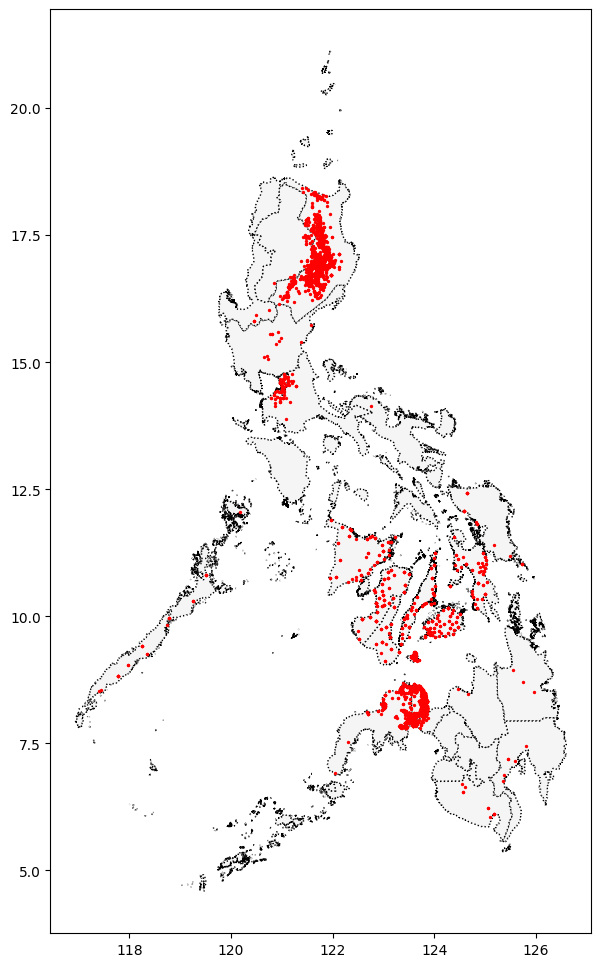

In [7]:
# Use the PHL and PHL_loans GeoDataFrames to visualize loans in the Philippines.
ax = PHL.plot(figsize=(12,12), color='whitesmoke', edgecolor='black', linestyle=':')
PHL_loans.plot(ax=ax, color='red', markersize=2, zorder=1)

In [8]:
from IPython.display import display, Markdown

content = f"""
**Q**: **Can you identify any islands where it might be useful to recruit new Field Partners? 
Do any islands currently look outside of Kiva's reach?**<br>
**A**: There are a number of potential islands, but Mindoro (in the central part of the Philippines) stands 
out as a relatively large island without any loans in the current dataset. 
This island is potentially a good location for recruiting new Field Partners!
"""

display(Markdown(content))


**Q**: **Can you identify any islands where it might be useful to recruit new Field Partners? 
Do any islands currently look outside of Kiva's reach?**<br>
**A**: There are a number of potential islands, but Mindoro (in the central part of the Philippines) stands 
out as a relatively large island without any loans in the current dataset. 
This island is potentially a good location for recruiting new Field Partners!
